## Data Utilities

Importing utilities and setting up environment:

In [41]:
import numpy as np
from matplotlib import pyplot as plt
import re
import os
from dotenv import load_dotenv

_ = load_dotenv()

from collections.abc import Iterable
from typing import Callable, TypeVar

T = TypeVar('T')
def identity(x: T) -> T:
  return x

from pyutil.entities import *

random_seed = 459632113 # for reproducibility

Write the path to your database file in the `.env` file

In [2]:
db_file = os.getenv('COMMON_DB_FILE')

Creating a session from the given file:

In [3]:
from sqlalchemy import create_engine
from sqlalchemy.orm import Session

eng = create_engine(f'sqlite:///data/{db_file}')
Base.metadata.create_all(eng)
session = Session(eng)
connection = eng.connect()

Assigning colors to statuses for charts:

In [4]:
from sqlalchemy import select

status_color: dict[NormalisedStatus, str] = {
  NormalisedStatus.accepted: '#3bcc56',
  NormalisedStatus.draft: 'yellow',
  NormalisedStatus.review: '#3b93cc',
  NormalisedStatus.superseded: '#802be0',
  NormalisedStatus.withdrawn: 'orange',
  NormalisedStatus.rejected: '#db1717',
  NormalisedStatus.unknown: 'gray'
}

All projects in a handy `dict`

In [116]:
projects: dict[int, Project] = {}
for project in session.scalars(select(Project)):
  projects[project.project_id] = project

# e.g. plain pull requests wrongly identified as proposals
useless_proposals: dict[int, set[str]] = {
  5: {'2672', '3878', '2682', '2456', '2299', '2177', '1905', '1970', '1981', '1902', '1900',
    '1706', '1704', '1656', '1569', '1165', '1097', '1088', '1013', '3195', '2994', '0978',
    '0868', '0899', '0923'}
}

In [100]:
"""
Gets all useful proposal IDs from a project
"""
def project_proposals(project_id: int) -> list[str]:
  return [prop_id for prop_id in session.scalars(select(Proposal.proposal_id)
    .where(Proposal.project_id.is_(project_id)))
    if (project_id, prop_id) not in useless_proposals]

## Simple Statistics

To get familiar with the data, I compute the distributions of proposals for each project, based on their current (most recent) status

In [101]:
from collections import Counter

"""
Counts the occurrences of each status in a list of proposals
"""
def status_counts(proposal_ids: list[tuple[int, str]]) -> Counter[NormalisedStatus]:
  status_counts: Counter[NormalisedStatus] = Counter()
  for proj_id, prop_id in proposal_ids:
    latest_status = session.scalar(select(ProposalStatus.normalised_status)
      .where(ProposalStatus.project_id.is_(proj_id))
      .where(ProposalStatus.proposal_id.is_(prop_id))
      .order_by(ProposalStatus.created_at.desc())
      .limit(1))
    if latest_status:
      status_counts[latest_status] += 1
  # status_stats[project.enhancement_proposal_name] = status_counts
  return status_counts

  # plt.title(f'{title} ({status_counts.total()} samples)')
  # plt.pie([s[1] for s in status_counts_ord],
  #   labels=[s[0].value for s in status_counts_ord],
  #   colors=[status_color[s[0]] for s in status_counts_ord],
  #   autopct='%1.1f%%')

In [8]:
"""
Plots the distributions of current statuses across the given projects
Returns total heights of bars
"""
def bar_statuses_for_projects(project_ids: Iterable[int]) -> list[int]:
  proj_names = [projects[proj_id].project_name for proj_id in project_ids]
  proj_stat_counts: list[Counter[NormalisedStatus]] = []
  for proj_id in project_ids:
    prop_ids = project_proposals(proj_id)
    proj_stat_counts.append(status_counts([(proj_id, prop_id)
      for prop_id in prop_ids]))

  bar_levels = np.zeros(len(proj_names), dtype=int)
  for stat in NormalisedStatus:
    stat_count = [cnt[stat] for cnt in proj_stat_counts]
    plt.bar(proj_names, stat_count, bottom=bar_levels, color=status_color[stat])
    bar_levels += stat_count
  
  return list(bar_levels)

Current status proportions:


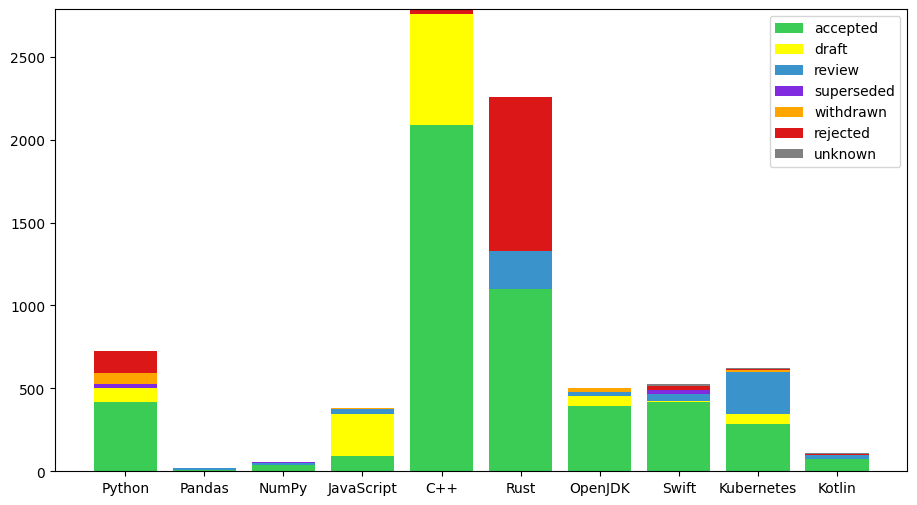

Status proportions (better view of small ones):


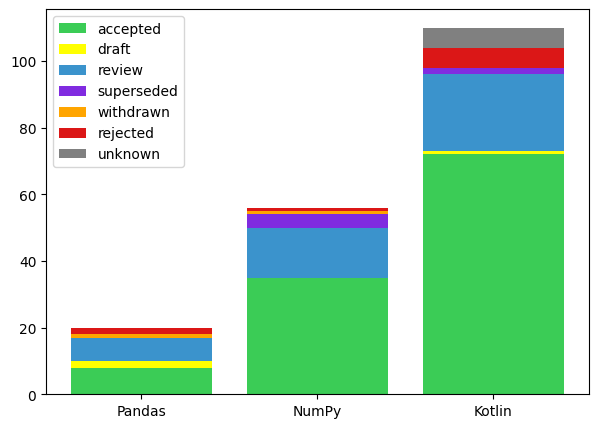

In [122]:
project_ids = projects.keys()

print('Current status proportions:')

plt.figure(figsize=(11,6))
bar_sizes = bar_statuses_for_projects(project_ids)
plt.legend([stat.value for stat in NormalisedStatus])
plt.show()

print('Status proportions (better view of small ones):')

max_size = max(bar_sizes)
plt.figure(figsize=(7,5))
bar_statuses_for_projects([p_id for i, p_id in enumerate(project_ids) if bar_sizes[i] * 10 < max_size])
plt.legend([stat.value for stat in NormalisedStatus])
plt.show()

In [120]:
proposals_with_topics = list(session.scalars(select(Proposal)
  .where(Proposal.topic.is_not(None))
  .where(Proposal.topic.is_not(''))))
projects_with_topics = list({p.project_id for p in proposals_with_topics})
print('IDs of projects with explicit proposal topics:', projects_with_topics)

IDs of projects with explicit proposal topics: [8, 9, 0]


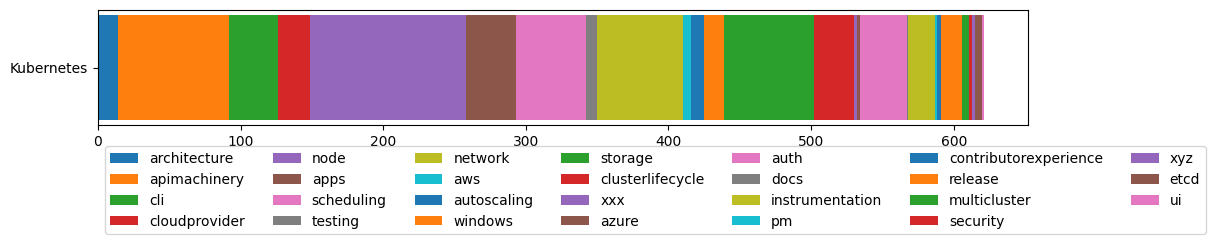

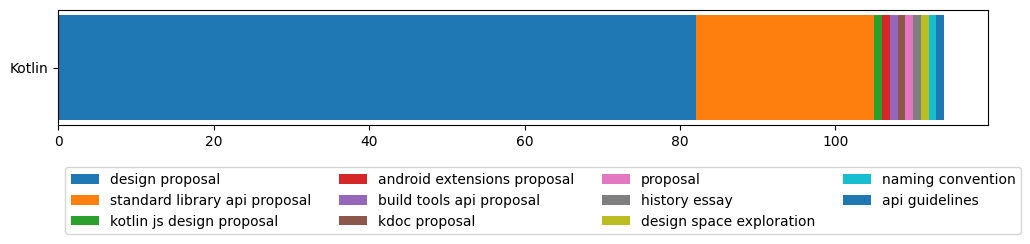

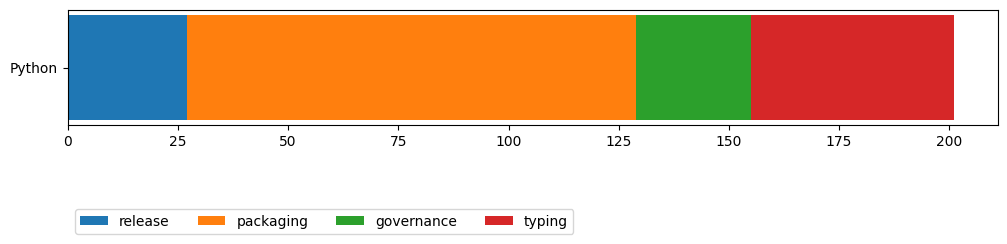

In [121]:
for proj_id in projects_with_topics:
  topic_counts = Counter[str]()
  for prop in proposals_with_topics:
    if prop.project_id == proj_id:
      assert prop.topic, f'Fetched proposal with no topic ({proj_id}, {prop.proposal_id})'
      for topic in re.split(r', | / ', prop.topic):
        topic_counts[topic.lower().replace('-', '')] += 1
  plt.figure(figsize=(12, 1.5))
  offset = 0
  for topic, count in topic_counts.items():
    _ = plt.barh([projects[proj_id].project_name], [count], left=offset, label=topic)
    offset += count
  _ = plt.legend(loc='lower left', bbox_to_anchor=(0, -1), ncol={0:4, 8:7, 9:4}[proj_id])
plt.show()

## Manual Reading

Picking the most popular proposals in each project, for me to manually read through and discover topics:

In [117]:
from sqlalchemy import func, text

num_to_take = 5

print('By number of comments:')
for proj_id, project in projects.items():
  # raw query because orm is painfully slow
  most_comments = session.execute(text(f'''select p.proposal_id from Proposal p join Comment c
    on p.project_id == c.project_id and p.proposal_id == c.proposal_id
    where p.project_id == :pid
    group by p.proposal_id
    order by count(c.comment_id) desc, p.proposal_id desc
    limit :lim'''), params={'pid': proj_id, 'lim': num_to_take})
  # most_comments = session.scalars(select(Proposal.proposal_id)
  #   .join(Comment, onclause=Proposal.project_id.is_(Comment.project_id) & Proposal.proposal_id.is_(Comment.proposal_id))
  #   .where(Proposal.project_id.is_(project.project_id))
  #   .group_by(Proposal.proposal_id)
  #   .order_by(func.count(Comment.comment_id).desc())
  #   .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {[c[0] for c in most_comments]}')

print('By number of revisions:')
for proj_id, project in projects.items():
  most_comments = session.scalars(select(ProposalRevision.proposal_id)
    .where(ProposalRevision.project_id.is_(proj_id))
    .where(ProposalRevision.proposal_id.not_in(useless_proposals.get(proj_id, set())))
    .group_by(ProposalRevision.proposal_id)
    .order_by(func.count(ProposalRevision.revision_index).desc())
    .order_by(ProposalRevision.proposal_id.desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

By number of comments:
PEP: ['8', '572', '517', '318', '426']
PDEP: []
NEP: ['14', '18', '20', '17', '41']
tc39: ['ShadowRealm', 'Updates to Tail Calls to include an explicit syntactic opt-in', 'Record & Tuple', 'Import Attributes', 'Temporal']
ISO C++: []
RFC: ['3946', '3892', '3855', '3834', '3830']
JEP: ['331', '472', '450', '8380294', '522']
Evolution: ['SE-0279', 'SE-0453', 'SE-0258', 'SE-0483', 'SE-0354']
KEP: ['4381', '3063', '4671', '3488', '127']
KEEP: ['0367', '0259', '0427', '0441', '0075']
By number of revisions:
PEP: ['11', '101', '1', '596', '619']
PDEP: ['1-1', '6-1', '10-1', '14-1', '12-1']
NEP: ['50', '35', '29', '18', '0']
tc39: ['Array.fromAsync', 'BigInt Math', 'Call-this operator', 'Bind-this operator', 'Pattern Matching']
ISO C++: ['P0447', 'P0876', 'P1018', 'P0260', 'P1928']
RFC: ['3537', '2873', '3389', '3503', '3502']
JEP: ['8377081', '401', '358', '430', '455']
Evolution: ['SE-0006', 'SE-0492', 'XX-0069', 'SE-0376', 'XX-0023']
KEP: ['1287', '3488', '4603', '10

Below are the manually identified topics from the proposals above:

In [130]:
sep_topics = {
  0: {
    '8': ['code style', 'advice'],
    '572': ['syntax'],
    '318': ['syntax', 'api structure'],
    '426': ['packaging'],
    '11': ['internal', 'compatibility'],
    '101': ['advice'],
    '1': ['meta'],
    '596': ['versioning', 'plan'],
    '619': ['versioning', 'plan'],
  },
  1: {
    '1-1': ['meta'],
    '6-1': ['typing'],
    '10-1': ['internal', 'typing', 'dev experience'],
    '14-1': ['typing'],
    '12-1': ['typing', 'api structure'],
  },
  2: {
    '14': ['deprecation'],
    '18': ['internal'],
    '20': ['syntax'],
    '17': ['api structure'],
    '41': ['typing', 'syntax'],
    '50': ['typing', 'dev experience'],
    '35': ['api structure', 'internal'],
    '29': ['versioning'],
    '0': ['meta'],
  },
  3: {
    'ShadowRealm': ['api structure'],
    'Updates to Tail Calls to include an explicit syntactic opt-in': ['syntax'],
    'Record & Tuple': ['syntax', 'typing'],
    'Import Attributes': ['syntax'],
    'Temporal': ['api structure'],
    'Array.fromAsync': ['api structure'],
    'BigInt Math': ['api structure'],
    'Call-this operator': ['syntax'],
    'Bind-this operator': ['syntax'],
    'Pattern Matching': ['syntax'],
  },
  5: {
    # '0078': ['dev experience'],
    # '0148': ['syntax'],
    # '0219': ['api structure', 'concurrency'],
    # '0235': ['api structure'],
    # '0439': ['api structure'],
    '3946': [],
    '3892': ['api structure'],
    '3855': ['dev experience'],
    '3834': ['syntax'],
    '3830': ['syntax'],
    '3537': ['versioning', 'packaging'],
    '2873': ['syntax'],
    '3389': ['syntax', 'packaging'],
    '3503': ['packaging'],
    '3502': ['packaging'],
  },
  6: {
    '331': ['performance', 'api structure'],
    '472': ['dev experience'],
    '450': ['performance', 'memory'],
    # '537': ['api structure'],
    # '223': ['versioning', 'dev experience', 'api structure'],
    '8380294': ['api structure', 'internal', 'performance'],
    '522': ['performance', 'concurrency'],
    # '533': ['concurrency', 'api structure'],
    # '506': ['api structure', 'performance'],
    # '454': ['memory', 'api structure'],
    # '352': ['syntax'],
    '8377081': ['security', 'api structure'],
    '401': ['internal', 'syntax'],
    '358': ['dev experience'],
    '430': ['syntax'],
    '455': ['syntax', 'typing'],
  },
  7: {
    'SE-0279': ['syntax'],
    'SE-0453': ['typing', 'api structure'],
    'SE-0258': ['syntax'],
    'SE-0483': ['typing', 'syntax'],
    'SE-0354': ['syntax'],
    'SE-0492': ['syntax'],
  },
  9: {
    '0367': ['syntax'],
    '0259': ['syntax'],
    '0427': ['syntax', 'typing'],
    '0441': ['syntax', 'typing'],
    '0075': ['syntax'],
    '0455': ['syntax'],
    '0452': ['internal', 'syntax'],
    '0430': ['syntax'],
    '0104': ['syntax', 'internal'],
  },
}

In [131]:
found_topic_counts = Counter[str]()
for proj_topics in sep_topics.values():
  for prop_topics in proj_topics.values():
    for prop_topic in prop_topics:
      found_topic_counts[prop_topic] += 1
print('Topics found at least twice:', [t for t, cnt in found_topic_counts.items() if cnt >= 2])

Topics found at least twice: ['advice', 'syntax', 'api structure', 'packaging', 'internal', 'meta', 'versioning', 'plan', 'typing', 'dev experience', 'performance']


In [134]:
topic_explanations = {
  'advice': 'Informational advice, such as code style guidelines',
  'syntax': 'About the built-in syntax of the language',
  'api structure': 'About pre-written code, such as libraries',
  'packaging': 'About the package manager and third-party packages of the language',
  'internal': 'About the inner code mechanisms that are not exposed to the user',
  'meta': 'About the software enhancement proposals themselves',
  'versioning': 'About version control, version naming scheme',
  'plan': 'About plans and schedules for maintainers',
  'typing': 'About the type system of the language or library',
  'dev experience': 'About features for the convenience of developers',
  'performance': 'About improvements to time, memory or power efficiency',
}

## Clustering

Step 1 - Fetching titles and contents of SEPs. Only considering the most recent ones

In [12]:
"""
Gets the latest revision of a proposal
None if a proposal has no revisions
"""
def proposal_latest_revision(project_id: int, proposal_id: str) -> ProposalRevision | None:
  return session.scalar(select(ProposalRevision)
    .where(ProposalRevision.project_id.is_(project_id))
    .where(ProposalRevision.proposal_id.is_(proposal_id))
    .order_by(ProposalRevision.created_at.desc())
    .limit(1))

def proposal_latest_content(project_id: int, proposal_id: str) -> str | None:
  rev = proposal_latest_revision(project_id, proposal_id)
  if rev is None: return None
  return rev.content

def proposal_latest_title(project_id: int, proposal_id: str) -> str | None:
  rev = proposal_latest_revision(project_id, proposal_id)
  if rev is None: return None
  return rev.title

Step 2 - Sanitization strategies for each project

In [42]:
def sanitize_markdown(content: str) -> str:
  return re.sub(r'<!--(?:(?!-->)[\s\S])+-->', '', # remove comments
    re.sub(r'```(?:(?!```)[\s\S])+```', '', # remove code blocks
    re.sub(r'\n\|[^\n]*', '', content))) # remove tables (lines starting with |)

def sanitize_pep(content: str) -> str:
  return re.sub(r'\n[^A-Za-z0-9\n]+\n', '\n', # remove lines with no alphanumeric characters
    re.sub(r'References\n[\s\S]*$|Copyright\n[\s\S]*$', '', content)) # remove everything starting from references or copyright section (usually nothing important)

def sanitize_pdep(content: str) -> str: # these are markdown
  return sanitize_markdown(content)

def sanitize_nep(content: str) -> str: # similar to pep
  return sanitize_pep(content)

def sanitize_rust(content: str) -> str:
  return re.sub(r'^[\s\S]*# Summary', '', # remove all before summary (metadata)
    sanitize_markdown(content))

def sanitize_jep(content: str) -> str:
  return re.sub(r'<code>(?:(?!</code>)[\s\S])+</code>', '', content) # remove code blocks

def sanitize_swift(content: str) -> str:
  return re.sub(r'^[\s\S]*# Introduction|^[\s\S]*# Summary', '', # remove all before introduction/summary (metadata)
    sanitize_markdown(content))

def sanitize_keep(content: str) -> str:
  return sanitize_markdown(content)

content_sanitizer = {
  0: sanitize_pep,
  1: sanitize_pdep,
  2: sanitize_nep,
  5: sanitize_rust,
  6: sanitize_jep,
  7: sanitize_swift,
  9: sanitize_keep,
}

"""
Cleans up the content of a proposal
Picks strategy based on which project it comes from
"""
def sanitize_content(project_id: int, content: str) -> str:
  sanitize = content_sanitizer.get(project_id, identity)
  return re.sub(r'[^A-Za-z0-9 .?!,]', ' ', # remove characters except alphanumeric, space and sentence separators
    re.sub(r'https?://\S+', '', # remove URLs
    sanitize(content)))

def sanitize_title_rust(title: str) -> str:
  return re.sub(r'^[Rr][Ff][Cc]:', '', title)

def sanitize_title_jep(title: str) -> str:
  return re.sub(r'^JEP\s+\S*\s*[:-]|^JEP:|^JEP XXX|^Draft\s+JEP:', '', title)

title_sanitizer = {
  5: sanitize_title_rust,
  6: sanitize_title_jep,
}

"""
Cleans up the title of a proposal
Picks strategy based on which project it comes from
"""
def sanitize_title(project_id: int, title: str) -> str:
  sanitize = title_sanitizer.get(project_id, identity)
  return re.sub(r'[^A-Za-z0-9 ]', ' ', # remove non-alphanum chars
    sanitize(title)).strip()

Step 3 - Splitting text into manageable sentence tokens. Titles remain in one piece

In [14]:
from nltk.tokenize import sent_tokenize

"""
Split content into sentences
Can specify what ratio of sentences to keep (0-1), starting from the first
"""
def tokenize_content(keep_ratio: float = 1.0) -> Callable[[str], list[str]]:
  def ratio_tok(clean_content: str) -> list[str]:
    sentences = sent_tokenize(clean_content)
    n = max(1, int(len(sentences) * keep_ratio))
    return sentences[:n]
  return ratio_tok

"""
Title is one sentence
"""
def tokenize_title(clean_title: str) -> list[str]:
  return [clean_title]

Step 4 - Embedding sentences into vectors using pre-trained models

In [15]:
from sentence_transformers import SentenceTransformer

Embedding = np.ndarray[tuple[int], np.dtype[np.float64]]

"""
Generate dense embedding, per sentence, using SBERT model
Specify save file to cache the result
Returns ndarray of sizes (n_sentences, n_dimensions)
"""
def generate_embedding(sentences: list[str], embedder: SentenceTransformer,
    save_file: str | None = None) -> np.ndarray[tuple[int, int], np.dtype[np.float64]]:
  embedding = None
  while embedding is None:
    embedding = embedder.encode(sentences, normalize_embeddings=True, convert_to_numpy=True, output_value='sentence_embedding')
    if np.any(np.isnan(embedding)):
      embedding = None
  if save_file is not None:
    np.save(open(save_file, 'wb'), embedding)
  return embedding

# Whether or not to cache embedding results
use_numpy_save = True

"""
Get embedding for a given proposal, with given sentences of text
Aggregates sentence embeddings by taking the mean
Can fetch embeddings from cache file or save them to it
Returns ndarray of size (n_dimensions,)
"""
def get_proposal_embedding(sentences: list[str], embedder: SentenceTransformer,
    project_id: int, proposal_id: str,
    embedder_name: str, strategy: str) -> Embedding:
  assert len(sentences) > 0, f'Empty content provided for embedding ({project_id}, {proposal_id}, {strategy})'
  sent_embeds = None
  if use_numpy_save:
    save_dir = f'cache/embeddings/{project_id}'
    os.makedirs(save_dir, exist_ok=True)
    file_name = f'{save_dir}/{proposal_id.replace('/', '')}-{embedder_name}-{strategy}.npy'
    try:
      sent_embeds = np.load(open(file_name, 'rb'))
    except:
      sent_embeds = generate_embedding(sentences, embedder, save_file=file_name)
  else:
    sent_embeds = generate_embedding(sentences, embedder)
  return np.mean(sent_embeds, axis=0)

Step 5 - Clustering the embeddings

In [16]:
from sklearn.base import ClusterMixin
from sklearn.cluster import KMeans

def kmeans(n: int, seed: int) -> ClusterMixin:
  return KMeans(n_clusters=n, random_state=seed)

In [17]:
ClusterLabel = np.int64

"""
Clusters embeddings using given clusterer strategy and target number of clusters
Returns label list of length n_embeds
"""
def cluster_embeds(embeds: Iterable[Embedding],
    clusterer: Callable[[int, int], ClusterMixin],
    num_clusters: int) -> Iterable[ClusterLabel]:
  return clusterer(num_clusters, random_seed).fit_predict(embeds)

In [18]:
# for each name of strategy: text extractor, sanitizer, tokenizer
embedding_strats = {
  'content': (proposal_latest_content, sanitize_content, tokenize_content()),
  'half_content': (proposal_latest_content, sanitize_content, tokenize_content(0.5)),
  '20_percent_content': (proposal_latest_content, sanitize_content, tokenize_content(0.2)),
  'title': (proposal_latest_title, sanitize_title, tokenize_title),
}

In [19]:
"""
Combiner function: sanitizes, tokenizes, embeds, clusters
Takes as input a list of project_id, proposal_id and associated text
Returns for each an embedding and a label, as parallel lists
"""
def cluster_texts(texts: Iterable[tuple[int, str, str]],
    embedder: SentenceTransformer,
    embedder_name: str,
    embedding_strat: str,
    clusterer: Callable[[int, int], ClusterMixin],
    num_clusters: int) -> tuple[list[Embedding], Iterable[ClusterLabel]]:
  _, sanitize, tokenize = embedding_strats[embedding_strat]
  token_lists = [(proj_id, prop_id, tokenize(sanitize(proj_id, text)))
      for proj_id, prop_id, text in texts]
  embeds = [get_proposal_embedding(tokens, embedder, proj_id, prop_id, embedder_name, embedding_strat)
    for proj_id, prop_id, tokens in token_lists]
  for i, e in enumerate(embeds):
    if np.any(np.isnan(e)): print(token_lists[i][1], embedding_strat, e)
  return embeds, cluster_embeds(embeds, clusterer, num_clusters)

In [20]:
"""
Gets the performance of the given clustering strategy on the given embeddings, for each cluster count
Returns score list of length len(cluster_counts)
"""
def clustering_performances(embeds: Iterable[Embedding],
    clusterer: Callable[[int, int], ClusterMixin],
    cluster_counts: list[int],
    performance_metric: Callable[[Iterable[Embedding], Iterable[ClusterLabel]], float]) -> list[float]:
  return [performance_metric(embeds, cluster_embeds(embeds, clusterer, num_clusters))
    for num_clusters in cluster_counts]

In [21]:
def plot_clust_performances(proposals: Iterable[tuple[int, str]],
    embedder: SentenceTransformer,
    embedder_name: str,
    clusterer: Callable[[int, int], ClusterMixin],
    cluster_counts: list[int],
    performance_metric: Callable[[Iterable[Embedding], Iterable[ClusterLabel]], float]):
  for strat_name, (get_text, _, _) in embedding_strats.items():
    maybe_texts = [(proj_id, prop_id, get_text(proj_id, prop_id))
      for proj_id, prop_id in proposals]
    texts = [(proj_id, prop_id, text) for proj_id, prop_id, text in maybe_texts if text is not None]
    embeds_labels = [cluster_texts(texts, embedder, embedder_name, strat_name, clusterer, num_clusters) for num_clusters in cluster_counts]
    scores = [performance_metric(embeds, labels) for embeds, labels in embeds_labels]
    plt.plot(cluster_counts, scores, label=strat_name)

In [22]:
# from sklearn.decomposition import PCA
# from matplotlib.axes._axes import Axes

# def plot_clust_performances(embeds: Iterable[Embedding],
#     labels: Iterable[ClusterLabel],
#     cluster_counts: list[int], title: str, ax: Axes):
#   scores: list[float] = []
#   for num_clusters in cluster_counts:
#     prop_labels = cluster_embeds(embeds)
#     assert prop_labels is not None, f'Clustering failed - {num_clusters} clusters'
#     scores.append(silhouette_score(embeds, prop_labels))
#   _ = ax.set_title(title)
#   _ = ax.plot(cluster_counts, scores)
#   _ = ax.set_ylim(bottom=0)
#   _ = ax.set(xlabel='cluster #', ylabel='silhouette score')

In [23]:
from sklearn.metrics import silhouette_score

def plot_clust_performance_on_project(project_id: int, embedder: SentenceTransformer, embedder_name: str):
  prop_ids = project_proposals(project_id)
  # prop_titles_contents = [proposal_latest_title_content(project_id, prop_id) for prop_id in prop_ids]
  # prop_ids_titles_contents = [(prop_ids[i], title_content[0], title_content[1])
  #   for i, title_content in enumerate(prop_titles_contents) if title_content is not None]
  # prop_ids_sentences = [(prop_id, [sanitize_title(project_id, title)], sent_tokenize(sanitize_content(project_id, content)))
  #   for prop_id, title, content in prop_ids_titles_contents]
  # title_embeds = [get_proposal_embedding(title, embedder, project_id, prop_id, embedder_name, 'title')
  #   for prop_id, title, _ in prop_ids_sentences]
  # content_embeds = [get_proposal_embedding(content, embedder, project_id, prop_id, embedder_name, 'content')
  #   for prop_id, _, content in prop_ids_sentences]
  # for i, e in enumerate(content_embeds):
  #   if np.any(np.isnan(e)): print(prop_ids_titles_contents[i][0], e)
  
  # cluster_counts = list(range(2, 15))
  # fig, (ax1, ax2) = plt.subplots(1, 2)
  # fig.set_figwidth(20)
  # _ = fig.suptitle(f'Clustering performance for embedding - {projects[project_id].project_name}')
  # plot_clust_performances(title_embeds, cluster_counts,
  #   f'Title-based', ax1)
  # plot_clust_performances(content_embeds, cluster_counts,
  #   f'Content-based', ax2)
  plt.title(f'Clustering performance with {embedder_name} embedder - {projects[project_id].project_name}')
  plot_clust_performances([(project_id, prop_id) for prop_id in prop_ids],
    embedder, embedder_name, kmeans, list(range(2, 15)), silhouette_score)
  plt.ylim(bottom=0)
  plt.xlabel('cluster #')
  plt.ylabel('silhouette score')
  plt.legend()
  plt.show()

I explore every project except C++, because of how different their paradigm is.

In [24]:
project_ids_to_explore = [proj_id for proj_id in projects if proj_id not in [4]]

In [27]:
minilm_embedder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', token=os.getenv('HF_TOKEN'))

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

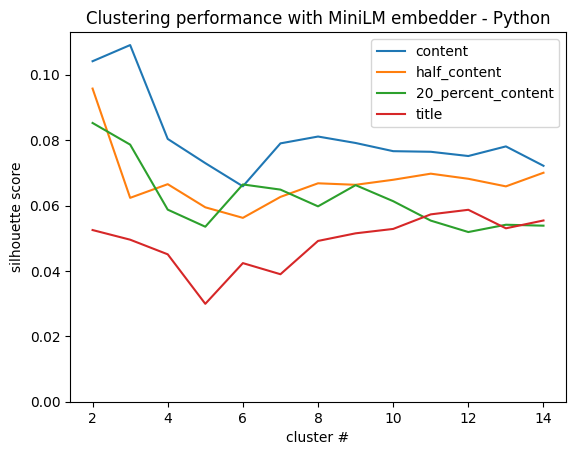

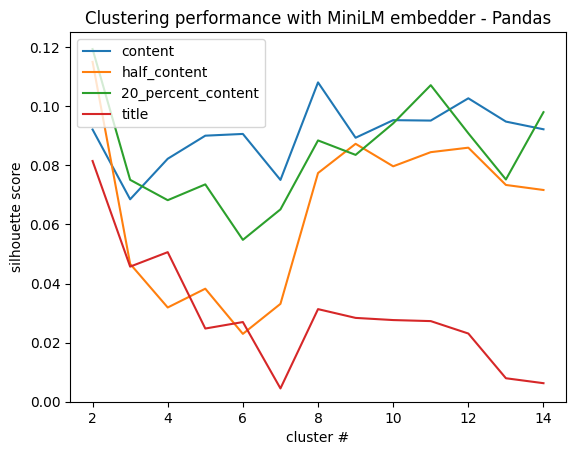

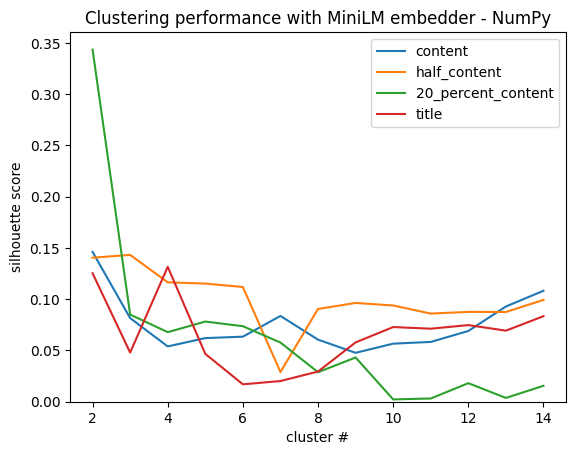

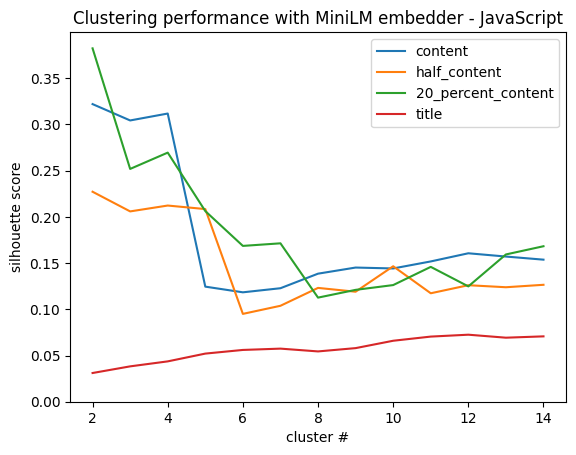

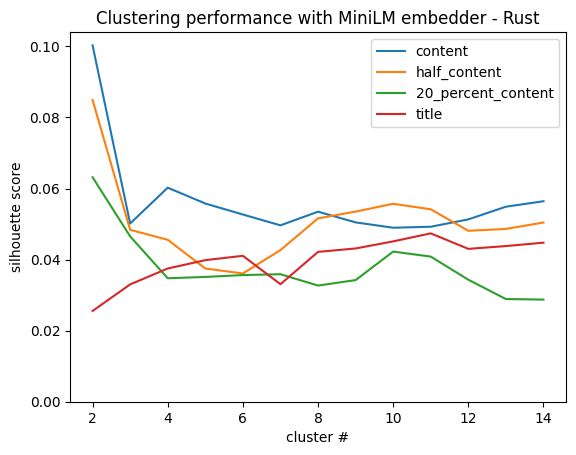

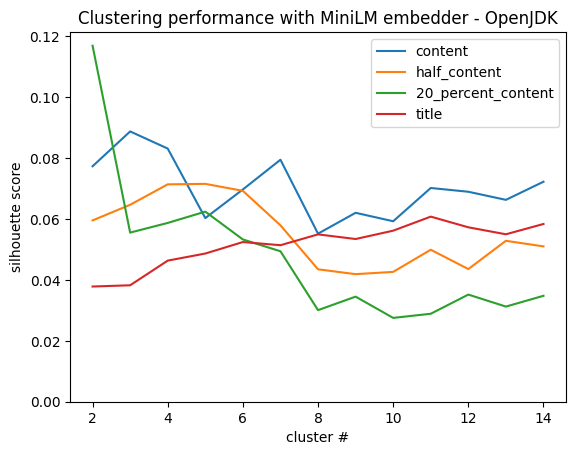

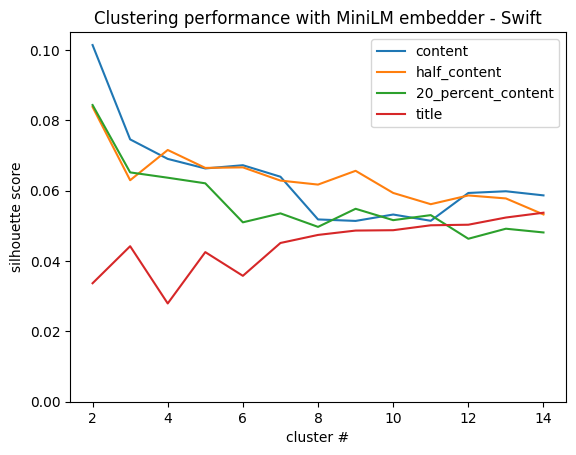

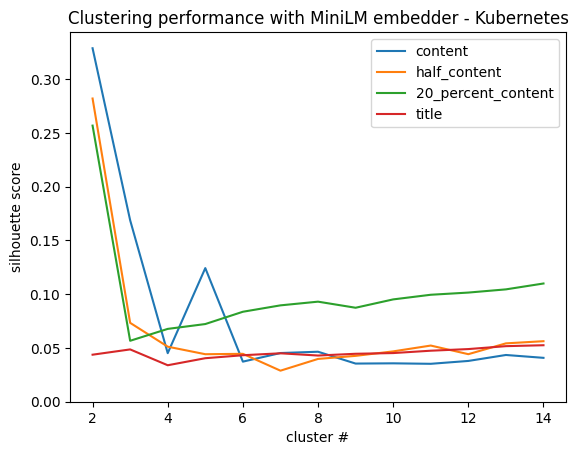

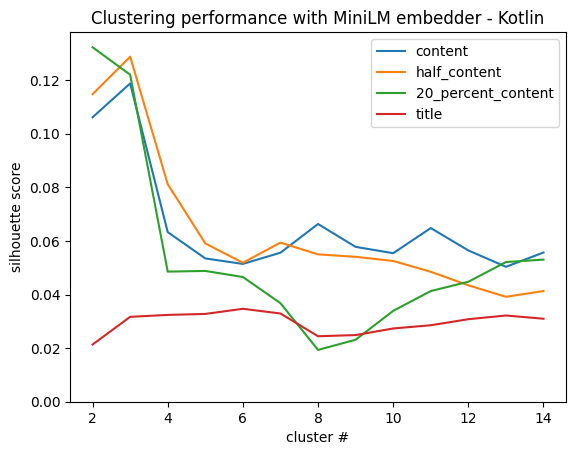

In [109]:
for proj_id in project_ids_to_explore:
  plot_clust_performance_on_project(proj_id, minilm_embedder, 'MiniLM')

In [25]:
mpnet_embedder = SentenceTransformer("all-mpnet-base-v2", token=os.getenv('HF_TOKEN'))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

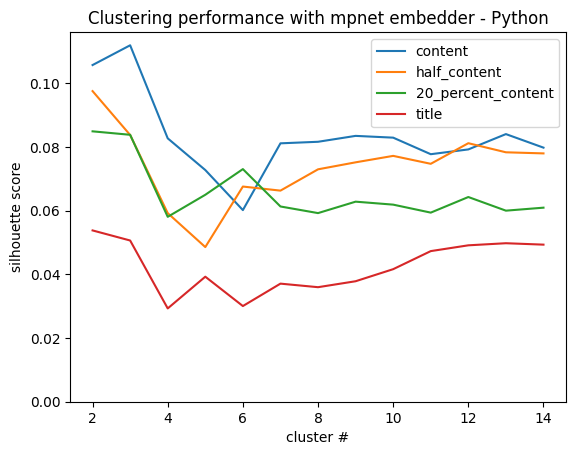

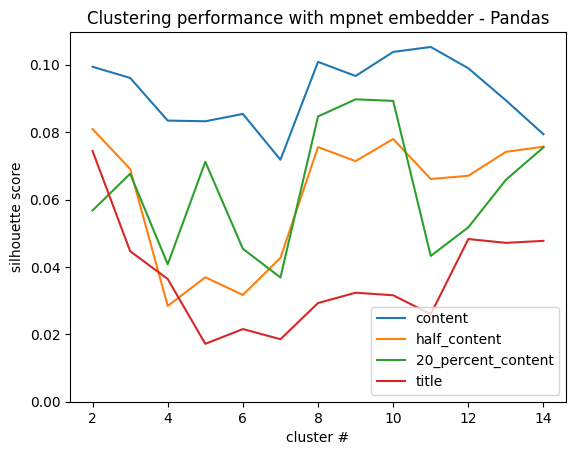

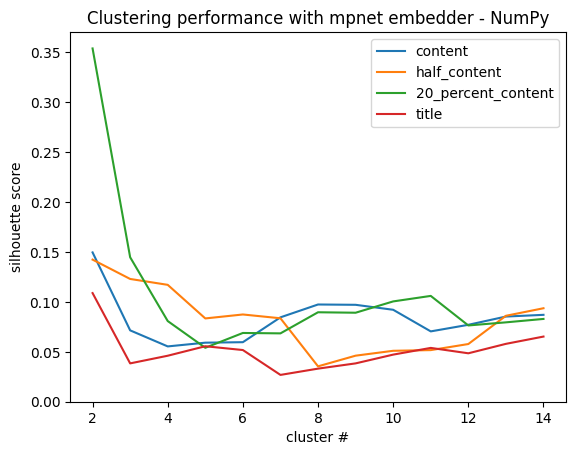

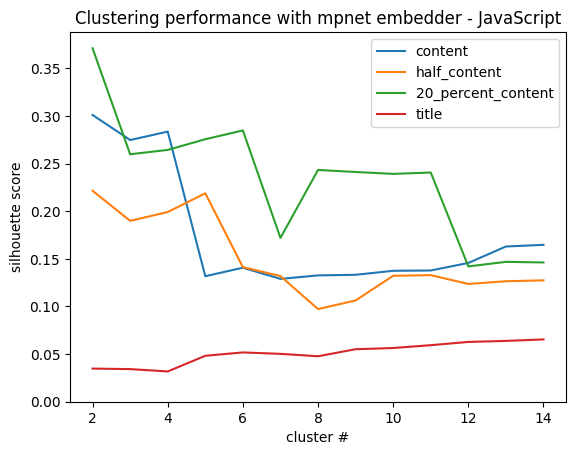

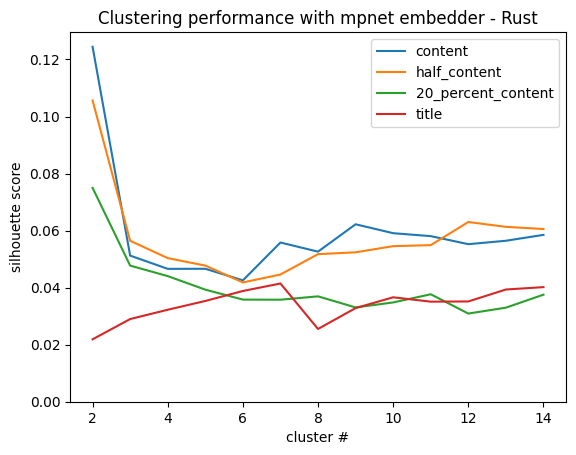

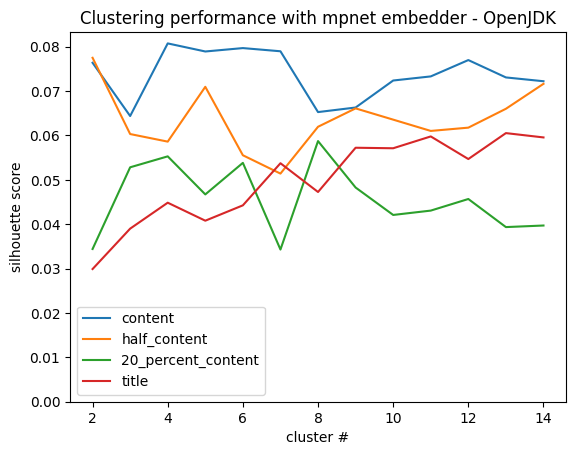

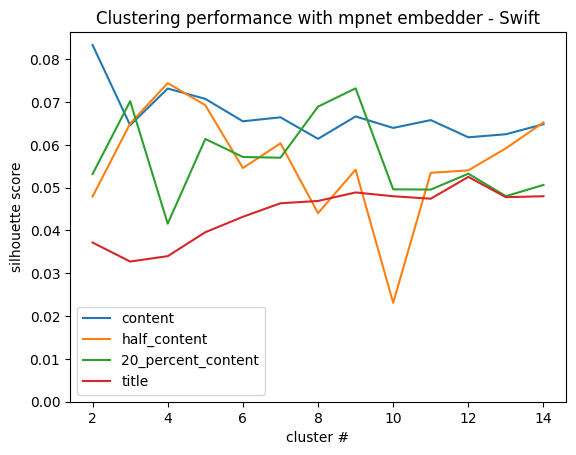

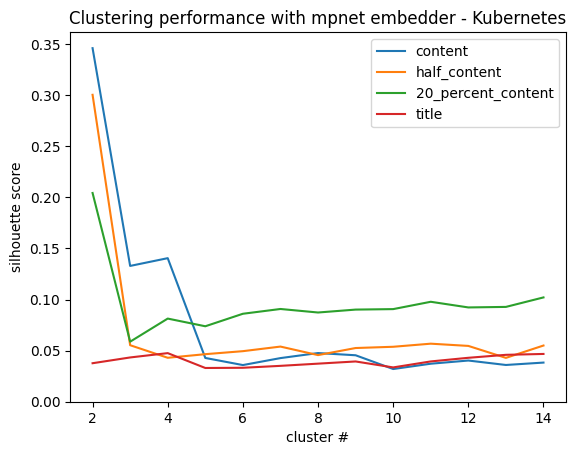

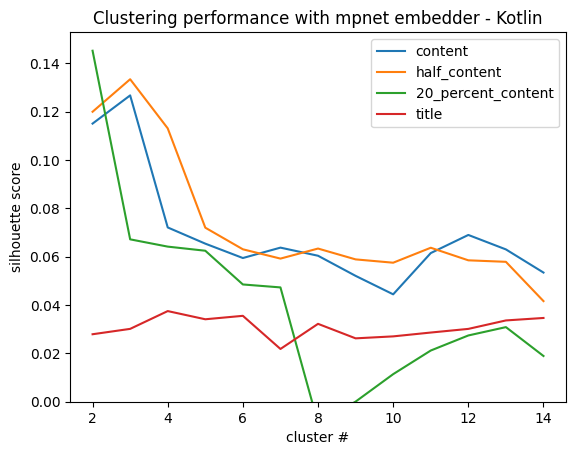

In [26]:
for proj_id in project_ids_to_explore:
  plot_clust_performance_on_project(proj_id, mpnet_embedder, 'mpnet')